In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

In [2]:
data = load_breast_cancer()
X = data.data
y = data.target

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca_full = PCA()
X_pca_full = pca_full.fit_transform(X_scaled)

evr = pca_full.explained_variance_ratio_
cum_evr = np.cumsum(evr)

n_95 = np.argmax(cum_evr >= 0.95) + 1
print(f"Original Dimensions: {X.shape[1]}")
print(f"Components needed for >=95% variance: {n_95} (reduction of {(1 - n_95/X.shape[1])*100:.1f}%)")

Original Dimensions: 30
Components needed for >=95% variance: 10 (reduction of 66.7%)


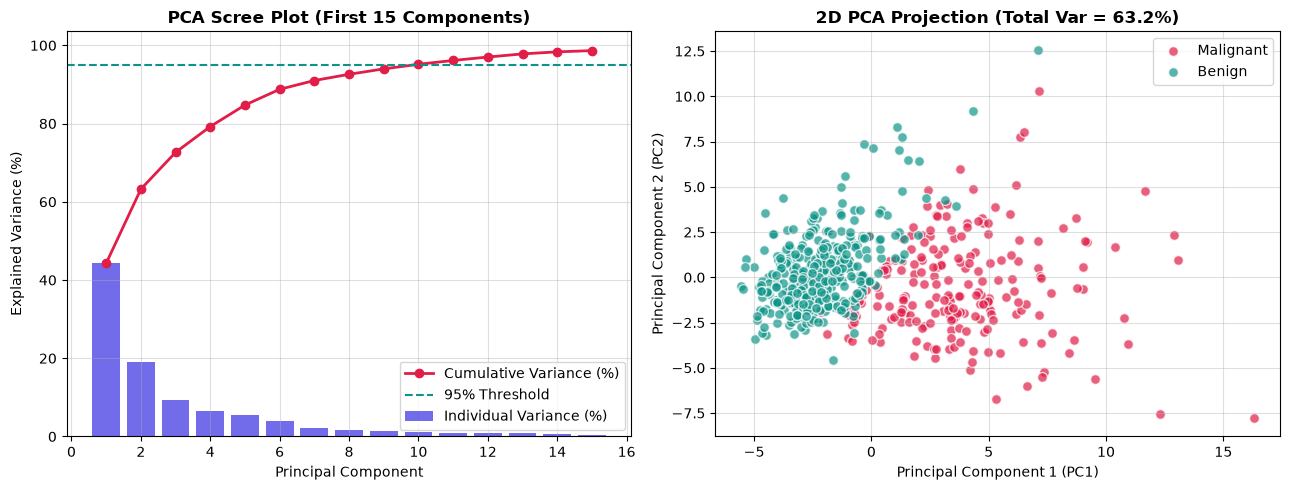

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Scree + Cumulative Variance
pcs = np.arange(1, len(evr) + 1)
ax1.bar(pcs[:15], evr[:15] * 100, color='#4F46E5', alpha=0.8, label='Individual Variance (%)')
ax1.plot(pcs[:15], cum_evr[:15] * 100, color='#E11D48', marker='o', lw=2, label='Cumulative Variance (%)')
ax1.axhline(95, color='#0D9488', linestyle='--', label='95% Threshold')
ax1.set_title('PCA Scree Plot (First 15 Components)', fontweight='bold')
ax1.set_xlabel('Principal Component'); ax1.set_ylabel('Explained Variance (%)')
ax1.legend(); ax1.grid(True, alpha=0.4)

# 2D Projection
pca_2d = PCA(n_components=2)
X_2d = pca_2d.fit_transform(X_scaled)
for cls, name, col in [(0, 'Malignant', '#E11D48'), (1, 'Benign', '#0D9488')]:
    mask = (y == cls)
    ax2.scatter(X_2d[mask, 0], X_2d[mask, 1], color=col, alpha=0.7, edgecolor='white', s=50, label=name)
ax2.set_title(f'2D PCA Projection (Total Var = {sum(pca_2d.explained_variance_ratio_)*100:.1f}%)', fontweight='bold')
ax2.set_xlabel('Principal Component 1 (PC1)')
ax2.set_ylabel('Principal Component 2 (PC2)')
ax2.legend(); ax2.grid(True, alpha=0.4)

plt.tight_layout()
plt.show()

In [4]:
X_tr, X_te, y_tr, y_te = train_test_split(X_scaled, y, test_size=0.2, random_state=42, stratify=y)

clf_full = LogisticRegression(max_iter=1000).fit(X_tr, y_tr)
acc_full = accuracy_score(y_te, clf_full.predict(X_te))

pca_95 = PCA(n_components=0.95)
X_tr_pca = pca_95.fit_transform(X_tr)
X_te_pca = pca_95.transform(X_te)
clf_pca = LogisticRegression(max_iter=1000).fit(X_tr_pca, y_tr)
acc_pca = accuracy_score(y_te, clf_pca.predict(X_te_pca))

print(f"Accuracy with All 30 Features        : {acc_full:.4f}")
print(f"Accuracy with {pca_95.n_components_} PCA Components (95%) : {acc_pca:.4f}")

Accuracy with All 30 Features        : 0.9825
Accuracy with 10 PCA Components (95%) : 0.9737
